# ✈️ TravelTide – Part 2: User-Level Features

**Masterschool (MSIT) Data Analytics – Mastery Project**

Part 1 cleaned the session table and checked the user-level SQL export. This notebook builds **one row per user** with the behavioral features the segments and perks are based on (Part 3).

**Inputs:** `user_level_table.csv` (SQL `user_base`, 5,998 users) and `sessions_clean.csv` (Part 1) for the few features the SQL does not have yet.
**Output:** `users_features.csv` – one row per user, used in Part 3 (segment rules, K-Means, DBSCAN), Tableau and Streamlit.

## 1 – Setup & Data Loading

In [11]:
import importlib, importlib.util, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
PALETTE = ["#3D90F3", "#A9CCF5", "#2E7D8C", "#1B4F8A", "#0D0F14", "#79B7F6"]
sns.set_palette(PALETTE)

# Theme gradient for charts with several groups (pale green-blue → TravelTide blue → navy)
from matplotlib.colors import LinearSegmentedColormap
TT_CMAP = LinearSegmentedColormap.from_list("traveltide", ["#DDF1E4", "#A8DDB5", "#4EB3D3", "#3D90F3", "#1B4F8A"])
def theme_shades(n):
    """n colors along the theme gradient – one shade per group, light to dark."""
    return [TT_CMAP(x) for x in np.linspace(0.15, 1, n)]

# Same data folder logic as Part 1: repo root, notebooks/ subfolder or Colab with Drive mounted
CANDIDATE_DIRS = [Path("data"), Path("../data"), Path("/content/drive/MyDrive/DS Mastery Project/data")]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.is_dir()), Path("data"))   # no folder yet → create data/ here
DATA_DIR.mkdir(exist_ok=True)
print("Data folder:", DATA_DIR.resolve())

# Google Drive backup (shared as "Anyone with the link – Viewer"), only used if a file is missing locally
DRIVE_IDS = {"user_level_table.csv": "1caT1H37JPzKNUo1EcM90eDIjHBe6nQG-",
             "sessions_clean.csv":   "1yvU9EUJkj92d_7y7-uLdbZY252Brkl8B"} 
def load_csv(name, **kwargs):
    if (DATA_DIR / name).exists():
        print(f"{name}: read from local folder")
        return pd.read_csv(DATA_DIR / name, **kwargs)
    if not DRIVE_IDS.get(name):
        raise FileNotFoundError(f"{name} is not in {DATA_DIR.resolve()} – run notebook 01 first (it creates this file).")
    print(f"{name}: not in the local folder → read from the Google Drive backup")
    return pd.read_csv(f"https://drive.google.com/uc?export=download&id={DRIVE_IDS[name]}", **kwargs)

users_raw = load_csv("user_level_table.csv", na_values=["NULL"])  # Load prepared user-level data for almost all analyses
sessions = load_csv("sessions_clean.csv", low_memory=False)       # only load cleaned sessions data for long_haul_share
print(f"Users: {len(users_raw):,} rows × {users_raw.shape[1]} columns | Sessions: {len(sessions):,} rows")

Data folder: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data
user_level_table.csv: read from local folder
sessions_clean.csv: read from local folder
Users: 5,998 rows × 29 columns | Sessions: 49,211 rows


## 2 – Format the user table
Same text rules as Part 1 (3.3), so labels match across notebooks, Tableau and Streamlit.

In [12]:
users = users_raw.copy()
users["home_city"] = users["home_city"].str.strip().str.title().str.replace(r"'(\w)", lambda m: "'" + m[1].lower(), regex=True)
users["home_airport"] = users["home_airport"].str.strip().str.upper()
users["home_country"] = users["home_country"].str.strip().map({"usa": "USA", "canada": "Canada"})
users["gender"] = users["gender"].str.strip().str.upper()
users = users.set_index("user_id")
users.head()

,age,gender,married,has_children,home_country,home_city,home_airport,tenure_months,session_count,avg_session_min,avg_page_clicks,cancelled_trips,valid_trips,flights,hotels,combo_share,flight_only_share,hotel_only_share,avg_seats,avg_rooms,avg_bags,avg_nights,avg_distance_km,weekend_start_share,discount_share,total_spend_usd,avg_spend_per_trip_usd,max_visits_same_city
user_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
23557,64,F,True,False,USA,New York,LGA,24,8,1.28,10.25,0,2,0,2,0.0,0.0,1.0,NaN,1.5,NaN,10.0,NaN,0.0,0.5,3670.50,1835.25,1
94883,51,F,True,False,USA,Kansas City,MCI,17,8,1.13,9.13,0,2,2,2,1.0,0.0,0.0,1.5,1.5,0.5,1.0,1454.0,0.0,0.0,1094.09,547.05,1
101486,50,F,True,True,USA,Tacoma,TCM,17,8,2.04,16.38,0,2,1,2,0.5,0.0,0.5,1.0,1.5,0.0,4.5,965.0,1.0,0.0,2641.91,1320.96,1
101961,42,F,True,False,USA,Boston,BOS,17,8,1.96,15.75,0,5,5,5,1.0,0.0,0.0,1.0,1.0,0.4,4.4,1322.0,0.4,0.2,4035.69,807.14,1
106907,44,F,True,True,USA,Miami,TNT,17,8,12.65,30.00,1,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


## 3 – Additional features
The SQL table already holds most trip metrics. Added here:
- **`family_status`** – 4 groups from `married` × `has_children` (describes segments)
- **`party_size`** – the larger of average seats and rooms (seats and rooms correlate at r = 0.98, Part 1 5.5.4 → one feature instead of two)
- **`long_haul_share`** – share of a user's flights over 3,000 km (Long-haul Travellers)
- **`is_dreamer`** – no valid trip (556 users)
- **`repeat_city`** – visited the same city at least twice (805 users, Favourite-City Returners)
- **`cancel_rate`** – share of a user's booked trips that were cancelled (cancelled ÷ (valid + cancelled))
- **`avg_discount_pct`** – average size of the discount on a user's valid bookings, in % (how *big*, while `discount_share` says how *often*); both count only discounts on the booked part (Part 1, 4.1)

In [13]:
users["family_status"] = np.select(
    [users["married"] & users["has_children"], users["married"], users["has_children"]],
    ["Married, children", "Married, no children", "Single, children"], default="Single, no children") # define family status based on married and has_children columns
users["party_size"] = users[["avg_seats", "avg_rooms"]].max(axis=1) # define party size as the maximum of average seats and average rooms
users["is_dreamer"] = users["valid_trips"] == 0 # define dreamers as users with no valid trip (never kept a booking)
users["repeat_city"] = users["max_visits_same_city"] >= 2 # define repeat-city users as those with 2 or more visits to the same city
users["cancel_rate"] = (users["cancelled_trips"] / (users["valid_trips"] + users["cancelled_trips"])).round(2) # share of booked trips that were cancelled

# discount depth: average discount on a user's valid bookings, in % – only discounts on the BOOKED part count
# (the session flags also show offers on the part not booked, see Part 1, 4.1 data note)
bookings = sessions[sessions["valid_booking"]]
flight_disc = bookings["flight_discount_amount"].where(bookings["flight_booked"] & bookings["flight_discount"])
hotel_disc = bookings["hotel_discount_amount"].where(bookings["hotel_booked"] & bookings["hotel_discount"])
users["avg_discount_pct"] = (pd.concat([flight_disc, hotel_disc], axis=1).max(axis=1)        # larger one if both were used
                             .groupby(bookings["user_id"]).mean().mul(100).round(1))

# long-haul share from the cleaned session table (valid bookings with a flight)
flights = sessions[sessions["valid_booking"] & sessions["distance_km"].notna()]
users["long_haul_share"] = (flights.assign(long_haul=flights["distance_km"] > 3000)
                            .groupby("user_id")["long_haul"].mean().round(2))   # define long-haul share as the proportion of long-haul flights per user

print("Dreamers:", users["is_dreamer"].sum(), "| repeat-city users:", users["repeat_city"].sum())

users[["party_size", "long_haul_share", "avg_bags", "avg_nights", "hotel_only_share", "weekend_start_share", "discount_share", "valid_trips"]].describe().round(2)

Dreamers: 556 | repeat-city users: 805


,party_size,long_haul_share,avg_bags,avg_nights,hotel_only_share,weekend_start_share,discount_share,valid_trips
count,5442.00,5045.00,5045.00,5302.00,5442.00,5442.00,5442.00,5998.00
mean,1.24,0.26,0.58,4.43,0.18,0.29,0.23,2.58
std,0.41,0.34,0.46,2.74,0.29,0.31,0.29,1.53
min,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.25,2.67,0.00,0.00,0.00,1.00
50%,1.00,0.00,0.50,3.75,0.00,0.25,0.00,3.00
75%,1.33,0.50,1.00,5.33,0.33,0.50,0.40,4.00
max,6.00,1.00,5.00,30.00,1.00,1.00,1.00,8.00


In [14]:
display(users["family_status"].value_counts().to_frame("users").assign(share_pct=lambda d: (d["users"] / d["users"].sum() * 100).round(1)))

,users,share_pct
family_status,,
"Single, no children",2482,41.4
"Married, no children",1558,26.0
"Married, children",1084,18.1
"Single, children",874,14.6


In [15]:
# Where the missing values come from (bookers only – Dreamers have no trip data at all)
bookers = users[~users["is_dreamer"]]
display(pd.DataFrame({
    "users": [(bookers["flights"] == 0).sum(),
              (bookers["hotels"] == 0).sum(),
              ((bookers["hotels"] > 0) & bookers["avg_nights"].isna()).sum()],
    "empty features": ["avg_bags, long_haul_share, avg_distance_km",
                       "avg_nights", "avg_nights"]},
    index=["Bookers without a valid flight (hotel-only)",
           "Bookers without a valid hotel (flight-only)",
           "Bookers whose hotel stays all had invalid dates (Part 1, 3.5)"]))

,users,empty features
Bookers without a valid flight (hotel-only),397,"avg_bags, long_haul_share, avg_distance_km"
Bookers without a valid hotel (flight-only),106,avg_nights
"Bookers whose hotel stays all had invalid dates (Part 1, 3.5)",34,avg_nights


Some features have fewer than 5,998 non-null values. I intentionally leave these as null (representing **"not applicable"**) rather than imputing `0`. The table above shows where each count comes from:

* **`avg_bags` & `long_haul_share`**: Null for **397** bookers (hotel-only bookers who took no valid flights) – plus the 556 Dreamers.
* **`avg_nights`**: Null for **140** bookers: **106** flight-only bookers who booked no hotel, and **34** whose hotel stays all had invalid dates (check-out on or before check-in, Part 1, 3.5).

Imputing `0` would incorrectly imply these users took flights with zero bags or booked zero-night hotel stays, which would artificially skew the behavioral metrics.

## 4 – First look at the behavioral features (bookers only)
Distributions of the features the segment rules will use. Dreamers are left out – they have no trip data.

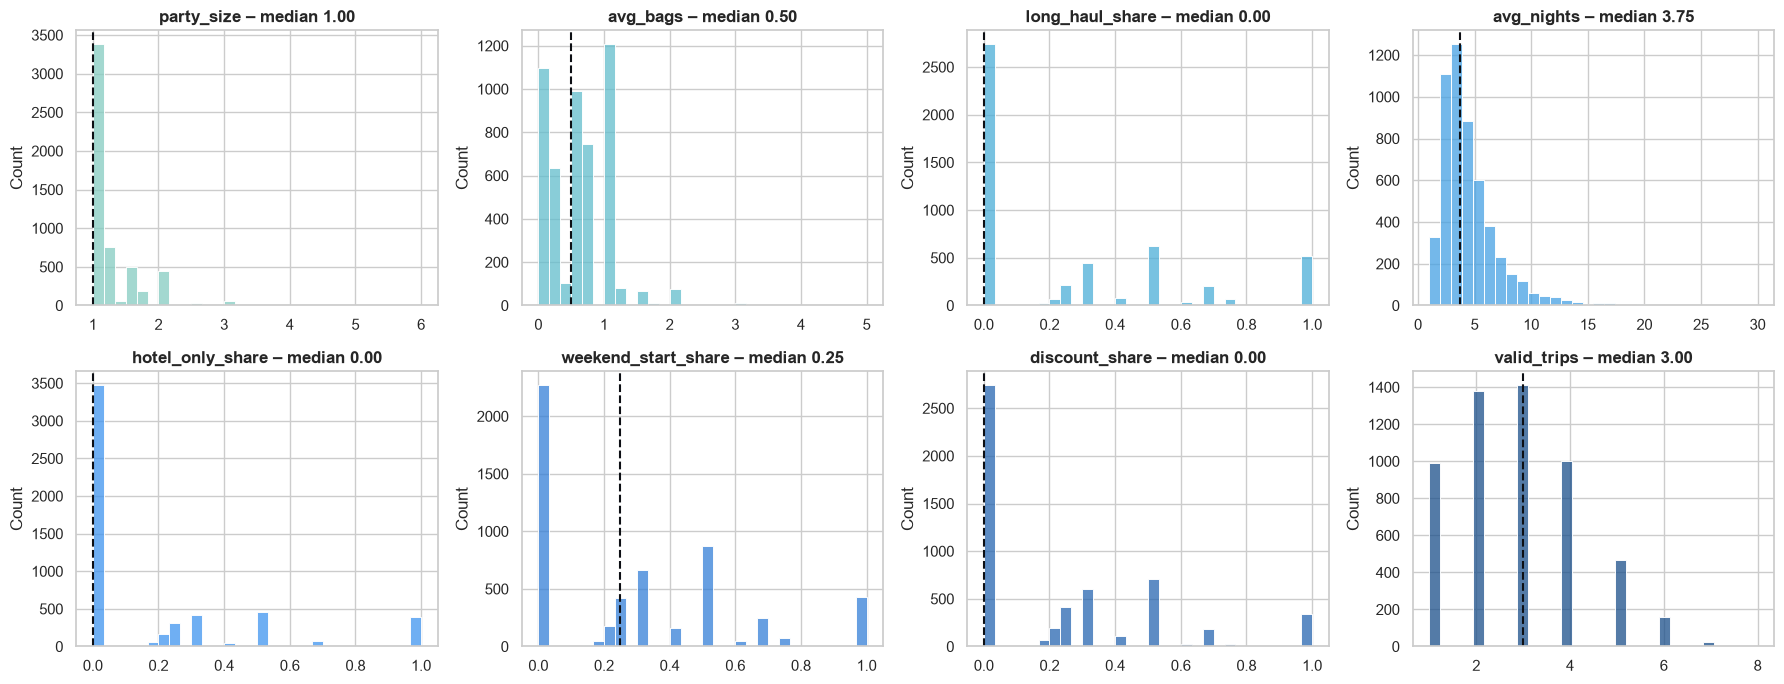

In [16]:
features = ["party_size", "avg_bags", "long_haul_share", "avg_nights", "hotel_only_share", "weekend_start_share", "discount_share", "valid_trips"]
bookers = users[~users["is_dreamer"]] # boookers exclude dreamers for the following plots
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
shades = [TT_CMAP(x) for x in np.linspace(0.35, 1, len(features))]   # one shade per feature (palest skipped – histograms are drawn semi-transparent)
for ax, col, shade in zip(axes.flat, features, shades):
    sns.histplot(bookers[col].dropna(), bins=30, ax=ax, color=shade)
    ax.axvline(bookers[col].median(), color=PALETTE[4], ls="--")
    ax.set_title(f"{col} – median {bookers[col].median():.2f}", fontweight="bold"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [21]:
# Numbers behind the bullets below
flyers = bookers["long_haul_share"].notna()
print(f"Party size ≥ 1.5:            {(bookers['party_size'] >= 1.5).sum():,} bookers")
print(f"≥ 1 long-haul flight:        {(bookers['long_haul_share'] > 0).sum():,} of {flyers.sum():,} flyers "
      f"({(bookers['long_haul_share'] > 0).sum() / flyers.sum():.0%})")
for col in ["hotel_only_share", "weekend_start_share", "discount_share"]:
    print(f"{col} ≥ 0.5: {(bookers[col] >= 0.5).mean():.1%} of bookers")

n_trips = bookers["valid_trips"]
print(f"Flight + hotel packages:     {(bookers['combo_share'] * n_trips).sum() / n_trips.sum():.1%} of all valid trips")
print(f"Only packages, ≥ 3 trips:    {((bookers['combo_share'] == 1) & (n_trips >= 3)).sum():,} bookers")

Party size ≥ 1.5:            1,246 bookers
≥ 1 long-haul flight:        2,299 of 5,045 flyers (46%)
hotel_only_share ≥ 0.5: 17.5% of bookers
weekend_start_share ≥ 0.5: 30.9% of bookers
discount_share ≥ 0.5: 23.5% of bookers
Flight + hotel packages:     74.7% of all valid trips
Only packages, ≥ 3 trips:    1,206 bookers


- Party size median of 1.0 confirms that most people travel alone.
- **1,246** bookers travel with an average party size of 1.5 or more – the base for **Family Crew** and **Couples & Friends**.
- Long-haul share has a median of 0, but 46% of flyers (2,299 of 5,045) have at least one long-haul flight. That’s the base for my **Long-haul Travellers** segment.
- Hotel-only share: 17.5% of bookers book hotel-only for at least half of their trips, which points to **Hotel Stayers**.
- Packages (flight + hotel) are 74.7% of all valid trips – the default way to travel. 1,206 bookers with 3+ trips book *only* packages, which is the base for my **Package Travellers** segment.
- Weekend start share (30.9% at ≥ 0.5) and discount share (23.5% at ≥ 0.5): both are spread out, so a threshold is needed to separate users. *(Part 3, section 3 later tests both against chance: they turn out to be luck – the weekend segment is dropped, discounts become the perk to test first.)*

This leads to the rules in notebook 03.

In [18]:
print(f"User table now: {users.shape[0]:,} rows × {users.shape[1]} columns")

User table now: 5,998 rows × 35 columns


## 5 – Which features say the same thing?
Correlation between the behavioral features (bookers only). Two features that move together would count twice in K-Means (Part 3), so only one of each pair is kept there.

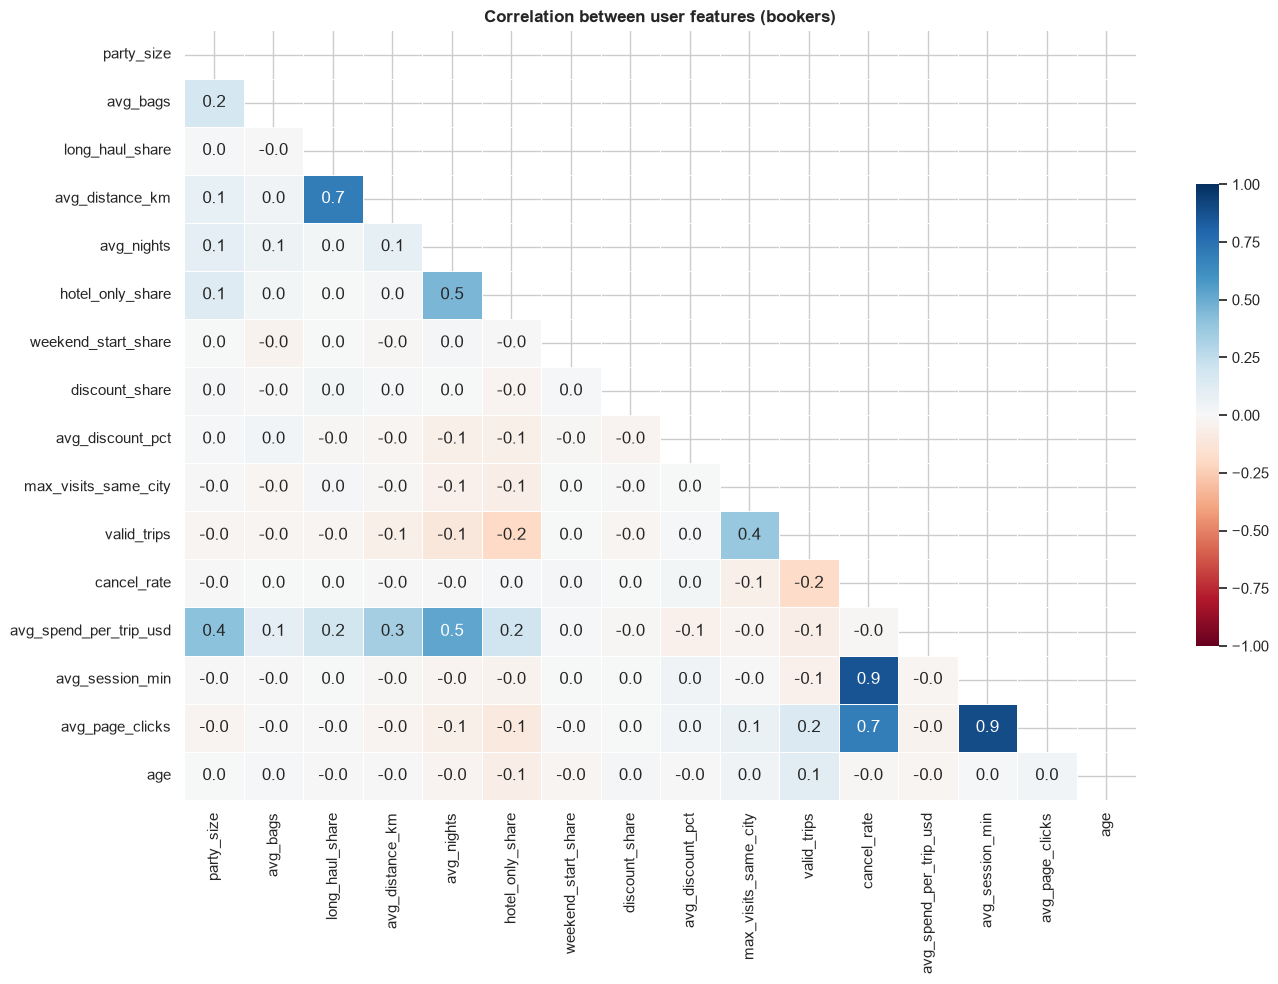

In [19]:
corr_cols = ["party_size", "avg_bags", "long_haul_share", "avg_distance_km", "avg_nights", "hotel_only_share",
             "weekend_start_share", "discount_share", "avg_discount_pct", "max_visits_same_city", "valid_trips",
             "cancel_rate", "avg_spend_per_trip_usd", "avg_session_min", "avg_page_clicks", "age"]
corr = users.loc[~users["is_dreamer"], corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the upper half (mirror image)
fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".1f", cmap="RdBu", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Correlation between user features (bookers)", fontweight="bold")
plt.tight_layout(); plt.show()

### Feature Correlations & Selection

There are only a few strongly correlated pairs (|r| ≥ 0.5):

* **`avg_session_min` & `avg_page_clicks` (~0.9):**  Longer sessions naturally have more clicks, so they carry the same signal. Together with the next two bullets, all three (session minutes, clicks, cancel rate) mainly reflect the cancellation sessions – so K-Means in notebook 03 keeps only cancel_rate, the most direct of the three.
* **`cancel_rate` & `avg_session_min` (~0.9):** This is driven mainly by the ~120-minute cancellation sessions flagged earlier (Part 1, 5.1.3), not by general slow browsing.
* **`cancel_rate` & `avg_page_clicks` (0.7):** Same cause as above – cancellation sessions stop at exactly 200 clicks (Part 1, 3.8), so users who cancel more also have higher average clicks.
* **`hotel_only_share` & `avg_nights` (~0.45, just below the threshold):** Hotel-only stays are about twice as long as package stays (median 6 vs 3 nights, Part 1, 5.4.3) – a behavior, not a duplicate signal, so both features stay.
* **`long_haul_share` & `avg_distance_km` (0.7):** Both just measure how far a user flies, so only one should be kept for K-Means in notebook 03 to avoid over-weighting distance.
* **`avg_nights` & `avg_spend_per_trip_usd` (0.5):** Longer stays cost more, which is expected.

All other pairs show weak correlations. This is ideal: the remaining features capture **distinct behaviors**, making them a solid foundation for user segmentation.

**Metrics considered but dropped:**

* *Booking rate* (trips ÷ sessions): Correlates at 0.99 with `valid_trips` because 82% of users have exactly 8 sessions.
* *Bags per seat:* Correlates at 0.91 with `avg_bags` and adds no new information.
* *Fare per km:* Fares are essentially fixed at ≈$0.18 per km/seat (from Part 1, 5.3.4), so this provides no useful variance.
* *Note on outliers & nulls:* Handled exactly as decided in Part 1 – outliers are kept as real trips (3.8), and nulls stay "not applicable" rather than being filled with 0 (3.4).

## 6 – Save

In [20]:
users.reset_index().to_csv(DATA_DIR / "users_features.csv", index=False)
print("Saved:", (DATA_DIR / "users_features.csv").resolve(), "|", users.shape)

Saved: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data\users_features.csv | (5998, 35)
